In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
data = {
    "Review_ID": range(1, 16),
    "Product": [
        "Laptop", "Laptop", "Laptop", "Laptop", "Laptop",
        "Phone", "Phone", "Phone", "Phone", "Phone",
        "Headphones", "Headphones", "Headphones", "Headphones", "Headphones"
    ],
    "Review": [
        "The laptop performance is excellent and the battery lasts long.",
        "The laptop is fast but the keyboard is uncomfortable.",
        "Poor build quality and very disappointing performance.",
        "Amazing display and smooth performance.",
        "The laptop is expensive but worth the price.",
        "The phone camera is excellent and the design is beautiful.",
        "Battery life is terrible and charging is very slow.",
        "Good performance but the phone gets hot.",
        "I love the display and the camera quality.",
        "The phone is overpriced and the battery is poor.",
        "Excellent sound quality and comfortable to wear.",
        "The headphones have poor sound and weak bass.",
        "Very comfortable and the audio is amazing.",
        "The price is high but the noise cancellation is excellent.",
        "Bad battery life and uncomfortable ear cushions."
    ]
}

df = pd.DataFrame(data)
display(df.head())
print("Total reviews:", len(df))

,Review_ID,Product,Review
0,1,Laptop,The laptop performance is excellent and the ba...
1,2,Laptop,The laptop is fast but the keyboard is uncomfo...
2,3,Laptop,Poor build quality and very disappointing perf...
3,4,Laptop,Amazing display and smooth performance.
4,5,Laptop,The laptop is expensive but worth the price.


Total reviews: 15


In [3]:
print("Dataset shape:", df.shape)
print("\nColumn information:")
df.info()

print("\nReviews per product:")
display(df["Product"].value_counts().to_frame("Number of Reviews"))

Dataset shape: (15, 3)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Review_ID  15 non-null     int64
 1   Product    15 non-null     str  
 2   Review     15 non-null     str  
dtypes: int64(1), str(2)
memory usage: 1.3 KB

Reviews per product:


,Number of Reviews
Product,
Laptop,5
Phone,5
Headphones,5


In [4]:
%pip install vaderSentiment


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\AMIT\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [5]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["Cleaned_Review"] = df["Review"].apply(clean_text)

display(df[["Review", "Cleaned_Review"]].head())

,Review,Cleaned_Review
0,The laptop performance is excellent and the ba...,the laptop performance is excellent and the ba...
1,The laptop is fast but the keyboard is uncomfo...,the laptop is fast but the keyboard is uncomfo...
2,Poor build quality and very disappointing perf...,poor build quality and very disappointing perf...
3,Amazing display and smooth performance.,amazing display and smooth performance
4,The laptop is expensive but worth the price.,the laptop is expensive but worth the price


In [6]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def analyze_sentiment(review):
    scores = analyzer.polarity_scores(review)
    compound = scores["compound"]

    if compound >= 0.05:
        sentiment = "Positive"
    elif compound <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    return pd.Series({
        "Positive_Score": scores["pos"],
        "Negative_Score": scores["neg"],
        "Neutral_Score": scores["neu"],
        "Compound_Score": compound,
        "Sentiment": sentiment
    })

sentiment_results = df["Review"].apply(analyze_sentiment)
df = pd.concat([df, sentiment_results], axis=1)

display(df[["Product", "Review", "Compound_Score", "Sentiment"]])

,Product,Review,Compound_Score,Sentiment
0,Laptop,The laptop performance is excellent and the ba...,0.5719,Positive
1,Laptop,The laptop is fast but the keyboard is uncomfo...,-0.5267,Negative
2,Laptop,Poor build quality and very disappointing perf...,-0.7645,Negative
3,Laptop,Amazing display and smooth performance.,0.5859,Positive
4,Laptop,The laptop is expensive but worth the price.,0.3291,Positive
5,Phone,The phone camera is excellent and the design i...,0.8225,Positive
6,Phone,Battery life is terrible and charging is very ...,-0.4767,Negative
7,Phone,Good performance but the phone gets hot.,0.2382,Positive
8,Phone,I love the display and the camera quality.,0.6369,Positive
9,Phone,The phone is overpriced and the battery is poor.,-0.4767,Negative


,Number of Reviews
Sentiment,
Positive,9
Negative,6


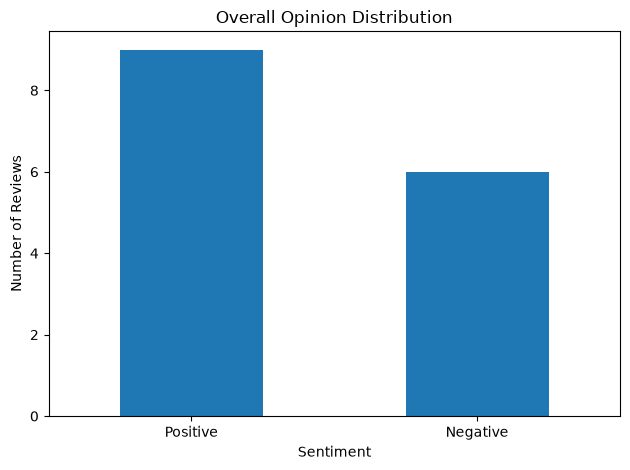

In [7]:
sentiment_counts = df["Sentiment"].value_counts()

display(sentiment_counts.to_frame("Number of Reviews"))

sentiment_counts.plot(
    kind="bar",
    title="Overall Opinion Distribution",
    xlabel="Sentiment",
    ylabel="Number of Reviews",
    rot=0
)

plt.tight_layout()
plt.show()

Sentiment,Negative,Positive
Product,,
Headphones,2,3
Laptop,2,3
Phone,2,3


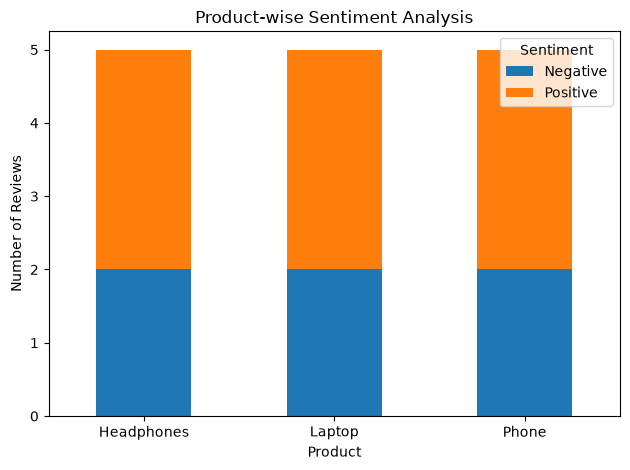

In [8]:
product_sentiments = pd.crosstab(
    df["Product"],
    df["Sentiment"]
)

display(product_sentiments)

product_sentiments.plot(
    kind="bar",
    stacked=True,
    title="Product-wise Sentiment Analysis",
    xlabel="Product",
    ylabel="Number of Reviews",
    rot=0
)

plt.tight_layout()
plt.show()

In [9]:
aspects = {
    "Performance": ["performance", "fast", "slow", "smooth"],
    "Battery": ["battery", "charging"],
    "Camera": ["camera"],
    "Display": ["display"],
    "Sound": ["sound", "audio", "bass"],
    "Comfort": ["comfortable", "uncomfortable", "cushions"],
    "Price": ["price", "expensive", "overpriced", "high"],
    "Build Quality": ["build quality", "design"],
    "Noise Cancellation": ["noise cancellation"]
}

def extract_aspects(review):
    review_lower = review.lower()
    found = []

    for aspect, keywords in aspects.items():
        if any(keyword in review_lower for keyword in keywords):
            found.append(aspect)

    return ", ".join(found) if found else "General Opinion"

df["Aspects"] = df["Review"].apply(extract_aspects)

display(df[["Product", "Review", "Aspects", "Sentiment"]])

,Product,Review,Aspects,Sentiment
0,Laptop,The laptop performance is excellent and the ba...,"Performance, Battery",Positive
1,Laptop,The laptop is fast but the keyboard is uncomfo...,"Performance, Comfort",Negative
2,Laptop,Poor build quality and very disappointing perf...,"Performance, Build Quality",Negative
3,Laptop,Amazing display and smooth performance.,"Performance, Display",Positive
4,Laptop,The laptop is expensive but worth the price.,Price,Positive
5,Phone,The phone camera is excellent and the design i...,"Camera, Build Quality",Positive
6,Phone,Battery life is terrible and charging is very ...,"Performance, Battery",Negative
7,Phone,Good performance but the phone gets hot.,Performance,Positive
8,Phone,I love the display and the camera quality.,"Camera, Display",Positive
9,Phone,The phone is overpriced and the battery is poor.,"Battery, Price",Negative


In [10]:
aspect_rows = []

for _, row in df.iterrows():
    for aspect in row["Aspects"].split(", "):
        if aspect != "General Opinion":
            aspect_rows.append({
                "Product": row["Product"],
                "Aspect": aspect,
                "Sentiment": row["Sentiment"],
                "Compound_Score": row["Compound_Score"]
            })

aspect_df = pd.DataFrame(aspect_rows)

if not aspect_df.empty:
    aspect_summary = (
        aspect_df.groupby(["Aspect", "Sentiment"])
        .size()
        .unstack(fill_value=0)
    )

    display(aspect_summary)
else:
    print("No aspects found.")

Sentiment,Negative,Positive
Aspect,,
Battery,3,1
Build Quality,1,1
Camera,0,2
Comfort,2,2
Display,0,2
Noise Cancellation,0,1
Performance,3,3
Price,1,2
Sound,1,2


,Mentions
Aspect,
Performance,6
Battery,4
Comfort,4
Price,3
Sound,3
Build Quality,2
Display,2
Camera,2
Noise Cancellation,1


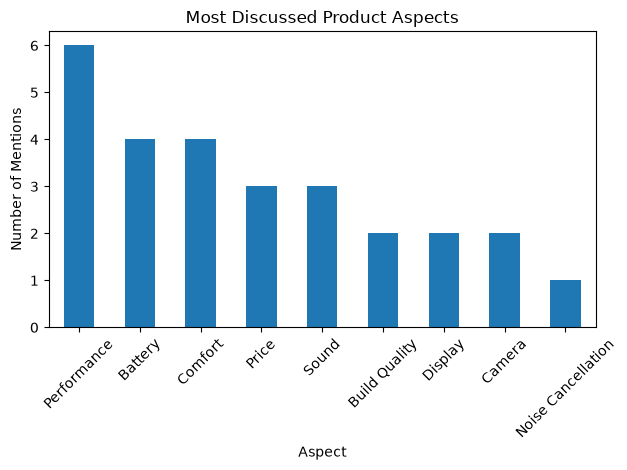

In [11]:
if not aspect_df.empty:
    aspect_counts = aspect_df["Aspect"].value_counts()

    display(aspect_counts.to_frame("Mentions"))

    aspect_counts.plot(
        kind="bar",
        title="Most Discussed Product Aspects",
        xlabel="Aspect",
        ylabel="Number of Mentions",
        rot=45
    )

    plt.tight_layout()
    plt.show()

In [12]:
custom_review = input("Enter a product review: ")

custom_scores = analyzer.polarity_scores(custom_review)
compound = custom_scores["compound"]

if compound >= 0.05:
    custom_sentiment = "Positive"
elif compound <= -0.05:
    custom_sentiment = "Negative"
else:
    custom_sentiment = "Neutral"

custom_aspects = extract_aspects(custom_review)

print("\nReview:", custom_review)
print("Sentiment:", custom_sentiment)
print("Compound Score:", round(compound, 3))
print("Aspect Scores:", custom_scores)
print("Detected Aspects:", custom_aspects)

Enter a product review:  positive



Review: positive
Sentiment: Positive
Compound Score: 0.557
Aspect Scores: {'neg': 0.0, 'neu': 0.0, 'pos': 1.0, 'compound': 0.5574}
Detected Aspects: General Opinion


In [13]:
output_file = "opinion_mining_results.csv"

df.to_csv(output_file, index=False)

print("Analysis saved successfully to:", output_file)
display(df.head())

Analysis saved successfully to: opinion_mining_results.csv


,Review_ID,Product,Review,Cleaned_Review,Positive_Score,Negative_Score,Neutral_Score,Compound_Score,Sentiment,Aspects
0,1,Laptop,The laptop performance is excellent and the ba...,the laptop performance is excellent and the ba...,0.291,0.000,0.709,0.5719,Positive,"Performance, Battery"
1,2,Laptop,The laptop is fast but the keyboard is uncomfo...,the laptop is fast but the keyboard is uncomfo...,0.000,0.298,0.702,-0.5267,Negative,"Performance, Comfort"
2,3,Laptop,Poor build quality and very disappointing perf...,poor build quality and very disappointing perf...,0.000,0.569,0.431,-0.7645,Negative,"Performance, Build Quality"
3,4,Laptop,Amazing display and smooth performance.,amazing display and smooth performance,0.487,0.000,0.513,0.5859,Positive,"Performance, Display"
4,5,Laptop,The laptop is expensive but worth the price.,the laptop is expensive but worth the price,0.251,0.000,0.749,0.3291,Positive,Price
